In [1]:
# NB-06: Satisfacción de Restricciones (CSP)
# Generado para: Andrés Hormazábal — UDP
# Parte del sistema de 25 notebooks de estudio ML/IA
# Fecha de generación: 2026-10-30

# NB-06: Satisfacción de Restricciones (CSP)

**Bloque:** 2 — IA Clásica (curso CIT-2013, AIMA)

**Base bibliográfica:** AIMA 4.ª ed., cap. 6 (*Constraint Satisfaction Problems*):
6.1 (definición), 6.2 (propagación y consistencia de arco), 6.3 (*backtracking* y
heurísticas), 6.4 (búsqueda local), 6.5 (estructura del problema) · Mackworth (1977)
para AC-3 · Dechter, *Constraint Processing*

**Prerequisitos:** NB-04 (DFS, búsqueda local, *hill climbing* y el problema de las
N reinas de §7.2 — aquí lo resolvemos otra vez, mucho mejor). NB-05 no es necesario.

## Objetivos de Aprendizaje

Al completar este notebook serás capaz de:

1. **Formular** un problema como CSP (variables, dominios, restricciones) y dibujar su
   grafo de restricciones.
2. **Explicar** por qué un CSP se resuelve mejor que con búsqueda genérica, usando el
   concepto de **representación factorizada**.
3. **Implementar** *backtracking* y las heurísticas **MRV**, **grado** y **LCV**, y
   **medir** cuánto aporta cada una.
4. **Implementar** *forward checking* y **AC-3**, y explicar la diferencia entre
   consistencia de nodo, de arco y de camino.
5. **Aplicar** *min-conflicts* y entender por qué resuelve 1.000.000 de reinas en
   segundos cuando el *backtracking* no pasa de unos cientos.
6. **Reconocer** cuándo la **estructura** del problema permite resolverlo en tiempo
   polinomial.

| Curso / Área | Relevancia |
|---|---|
| IA (CIT-2013) | **Materia de la Solemne 2** (AIMA cap. 6). Se pregunta ejecutar AC-3 a mano y aplicar MRV/LCV sobre un grafo dado. |
| Big Data (CIT-2309) | Programar la feria (charlas ↔ escenarios ↔ horarios) es un CSP: §8.3. También: asignación de particiones a nodos con restricciones de réplica. |
| Comunicaciones / Tesis | Asignación de frecuencias a antenas sin interferencia es el CSP canónico (coloreo de grafos). Asignación de códigos y planificación de recursos. |
| Notebooks relacionados | NB-04 (base: DFS y búsqueda local), NB-05 (juegos), NB-08 (redes bayesianas: mismo grafo, otra semántica), NB-22 (planificación de tareas) |

## Tabla de contenidos

1. Marco teórico: qué es un CSP y por qué merece algoritmos propios
2. Configuración
3. Un marco de CSP reutilizable
4. *Backtracking* y las heurísticas de ordenamiento
5. Inferencia: *forward checking* y AC-3
6. Búsqueda local: *min-conflicts*
7. La estructura del problema
8. Tres casos: Australia, Sudoku y la programación de una feria
9. Tabla comparativa y árbol de decisión
10. 📋 Cheat Sheet
11. Conexiones con el mundo real
12. Ejercicios progresivos
13. Resumen y siguiente paso

## 1. Marco teórico: qué es un CSP y por qué merece algoritmos propios

### La intuición: el estado deja de ser una caja negra

En NB-04, un estado era **atómico**: `"Arad"`, o un tablero del 8-puzzle. El algoritmo
solo podía hacer dos cosas con él: compararlo con la meta y generar sus sucesores. No
había forma de *mirar dentro*.

Un CSP usa una **representación factorizada**: el estado es un conjunto de
**variables con valores**. Y eso cambia todo, porque ahora el algoritmo puede razonar
sobre la estructura:

| Lo que permite la factorización | Qué ganas |
|---|---|
| Ver **qué variable** causó el fallo | podar ramas enteras en vez de una hoja |
| Ver **cuántos valores** le quedan a cada variable | elegir primero la más restringida (MRV) |
| **Propagar** una decisión a los vecinos | descubrir fallos antes de cometerlos |
| Ver el **grafo** de restricciones | explotar su forma (§7) |

> **Idea clave, y la frase que hay que saber decir en la prueba.** Un CSP no es un
> problema de búsqueda "más fácil": es un problema de búsqueda en el que **el algoritmo
> puede inspeccionar la estructura del estado**, y toda la ganancia viene de ahí.

### Los tres componentes

$$\text{CSP} = \langle X, D, C\rangle$$

- $X=\{X_1,\dots,X_n\}$: las **variables**.
- $D=\{D_1,\dots,D_n\}$: el **dominio** de cada una (los valores posibles).
- $C$: las **restricciones**, cada una sobre un subconjunto de variables.

Una **solución** es una asignación **completa** (todas las variables) y **consistente**
(no viola ninguna restricción).

### Tipos de restricción

| Tipo | Alcance | Ejemplo | Qué hacer con ella |
|---|---|---|---|
| **Unaria** | 1 variable | $SA \ne \text{verde}$ | se aplica **una vez**, podando el dominio |
| **Binaria** | 2 variables | $WA \ne NT$ | es el caso estándar; da el **grafo** |
| **Global** | $n$ variables | `Alldiff(X1..X9)` | se puede descomponer en binarias, pero se pierde poder de propagación |

El **grafo de restricciones** tiene un nodo por variable y una arista por restricción
binaria. Es el objeto central del capítulo: casi todo lo que sigue es explotarlo.

```
      Coloreo de Australia (el ejemplo de AIMA 6.1)

           NT ──── Q                 Variables: WA, NT, SA, Q, NSW, V, T
          /  \    /  \               Dominios : {rojo, verde, azul}
        WA ── SA ──── NSW            Restricción: regiones vecinas,
          \   |      /                            distinto color
           \  |     /
             V ────┘                 T (Tasmania) no toca a nadie:
                                     es una componente aparte
           T  (aislada)
```

### ¿Por qué no usar simplemente DFS de NB-04?

Podrías: asigna una variable, luego otra, retrocede si falla. Pero sin mirar la
estructura caes en dos desperdicios enormes:

1. **El orden no importa, pero el DFS no lo sabe.** Asignar $WA$ y luego $NT$ lleva al
   mismo sitio que al revés. Un DFS ingenuo trata ambas rutas como distintas y explora
   $n!$ órdenes de un espacio que solo tiene $d^n$ asignaciones.
2. **Descubre los fallos tarde.** Si asignar $WA=\text{rojo}$ deja a $SA$ sin valores
   posibles, un DFS lo averigua varios niveles más abajo, tras construir medio árbol
   inútil.

El *backtracking* para CSP arregla (1) fijando un orden de variables, y la
**propagación** arregla (2).

## 2. Configuración

In [2]:
# === Imports ===
import itertools
import random
import time
from collections import deque, defaultdict
from dataclasses import dataclass, field

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import seaborn as sns
from IPython.display import display

SEED = 42
random.seed(SEED)
rng = np.random.default_rng(SEED)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "figure.figsize": (9, 4.5),
                     "axes.titlesize": 12, "grid.alpha": 0.35})
pd.set_option("display.max_columns", 30)
print(f"NumPy {np.__version__} | pandas {pd.__version__} | networkx {nx.__version__}")

NumPy 2.5.4 | pandas 3.1.0 | networkx 3.7


## 3. Un marco de CSP reutilizable

Mismo principio que `Problem` (NB-04) y `Game` (NB-05): **el algoritmo no conoce el
dominio**. Definimos el CSP con restricciones binarias dadas como una función
`consistente(A, a, B, b)`, que es la forma que usa AIMA.

Variables: ['WA', 'NT', 'SA', 'Q', 'NSW', 'V', 'T']
Dominio de cada una: ['rojo', 'verde', 'azul']
Espacio de búsqueda bruto: 3^7 = 2,187 asignaciones completas


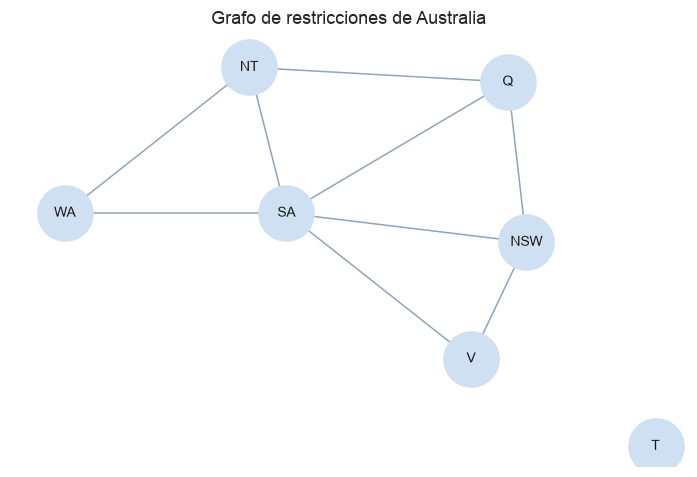

Grados (nº de vecinos): {'SA': 5, 'NT': 3, 'Q': 3, 'NSW': 3, 'WA': 2, 'V': 2, 'T': 0}

  SA toca a 5 regiones: es la variable más restringida del problema. Guárdate
  ese dato, porque la heurística de GRADO de §4.3 lo va a usar y va a decidir
  por dónde empezar.


In [3]:
@dataclass
class Metricas:
    """Sin esto, 'MRV ayuda' es una opinión. Con esto, es un número."""
    asignaciones: int = 0        # cuántas veces se asignó un valor a una variable
    retrocesos: int = 0          # cuántas veces hubo que deshacer
    podas: int = 0               # valores eliminados por inferencia
    def reset(self): self.asignaciones = self.retrocesos = self.podas = 0


class CSP:
    """CSP con restricciones BINARIAS (AIMA 6.1).

    variables : lista de nombres
    dominios  : dict var -> lista de valores
    vecinos   : dict var -> lista de vars con las que comparte restricción
    consistente(A, a, B, b) -> bool : ¿la asignación A=a es compatible con B=b?
    """

    def __init__(self, variables, dominios, vecinos, consistente):
        self.variables = list(variables)
        self.dominios = {v: list(d) for v, d in dominios.items()}
        self.vecinos = vecinos
        self.consistente = consistente
        self.m = Metricas()

    def conflictos(self, var, val, asignacion) -> int:
        """Cuántos vecinos YA asignados entran en conflicto con var=val."""
        return sum(1 for v in self.vecinos[var]
                   if v in asignacion and not self.consistente(var, val, v, asignacion[v]))

    def es_consistente(self, var, val, asignacion) -> bool:
        return self.conflictos(var, val, asignacion) == 0

    def completa(self, asignacion) -> bool:
        return len(asignacion) == len(self.variables)

    def verificar(self, asignacion) -> bool:
        """Verificación INDEPENDIENTE de la solución. Nunca confíes en que el
        solver tiene razón: compruébalo con código que no comparte su lógica."""
        if not self.completa(asignacion): return False
        return all(self.consistente(a, asignacion[a], b, asignacion[b])
                   for a in self.variables for b in self.vecinos[a])

    def grafo(self):
        G = nx.Graph()
        G.add_nodes_from(self.variables)
        for a in self.variables:
            for b in self.vecinos[a]:
                G.add_edge(a, b)
        return G


def csp_australia():
    """El ejemplo canónico de AIMA 6.1: colorear Australia con 3 colores."""
    vecinos = {
        "WA": ["NT", "SA"], "NT": ["WA", "SA", "Q"], "SA": ["WA", "NT", "Q", "NSW", "V"],
        "Q": ["NT", "SA", "NSW"], "NSW": ["Q", "SA", "V"], "V": ["SA", "NSW"], "T": [],
    }
    colores = ["rojo", "verde", "azul"]
    return CSP(list(vecinos), {v: colores for v in vecinos}, vecinos,
               lambda A, a, B, b: a != b)


aus = csp_australia()
print(f"Variables: {aus.variables}")
print(f"Dominio de cada una: {aus.dominios['WA']}")
print(f"Espacio de búsqueda bruto: 3^7 = {3**7:,} asignaciones completas")

fig, ax = plt.subplots(figsize=(6.5, 4.5))
G = aus.grafo()
pos = {"WA": (0, 1), "NT": (1, 2), "Q": (2.4, 1.9), "SA": (1.2, 1), "NSW": (2.5, .8),
       "V": (2.2, 0), "T": (3.2, -.6)}
nx.draw_networkx(G, pos, ax=ax, node_color="#cfe0f3", node_size=1300,
                 edge_color="#8fa5bd", font_size=9)
ax.set(title="Grafo de restricciones de Australia"); ax.axis("off")
plt.tight_layout(); plt.show()
print(f"Grados (nº de vecinos): "
      f"{dict(sorted(dict(G.degree()).items(), key=lambda kv: -kv[1]))}")
print("""
  SA toca a 5 regiones: es la variable más restringida del problema. Guárdate
  ese dato, porque la heurística de GRADO de §4.3 lo va a usar y va a decidir
  por dónde empezar.""")

## 4. *Backtracking* y las heurísticas de ordenamiento

### 4.1 El algoritmo base

*Backtracking* es **DFS con dos reglas añadidas**: se asigna **una variable por nivel**
(lo que elimina las permutaciones redundantes) y se **comprueba la consistencia antes
de bajar**.

```
función BACKTRACK(asignación, csp):
    si asignación está completa: devolver asignación
    var ← SELECCIONAR-VARIABLE-NO-ASIGNADA(csp, asignación)      ← MRV / grado
    para cada val en ORDENAR-VALORES(var, asignación, csp):      ← LCV
        si val es consistente con asignación:
            añadir {var = val}
            inferencias ← INFERIR(csp, var, val)                 ← FC / MAC
            si inferencias ≠ fallo:
                resultado ← BACKTRACK(asignación, csp)
                si resultado ≠ fallo: devolver resultado
            deshacer var e inferencias
    devolver fallo
```

Las tres mayúsculas son exactamente las tres palancas del capítulo:

| Palanca | Pregunta que responde | Heurística |
|---|---|---|
| Qué variable asigno ahora | ¿cuál falla antes? | **MRV**, desempate por **grado** |
| En qué orden pruebo los valores | ¿cuál deja más opciones? | **LCV** |
| Qué deduzco tras asignar | ¿qué se vuelve imposible? | **forward checking**, **AC-3/MAC** |

### 4.2 MRV: *Minimum Remaining Values* — "falla primero"

**Elige la variable con menos valores legales restantes.**

El razonamiento es contraintuitivo al principio: ¿por qué atacar lo más difícil
primero? Porque si una variable va a fallar, **quieres descubrirlo arriba del árbol**,
donde podar cuesta poco. Si la dejas para el final, habrás construido todo el subárbol
antes de descubrir que no servía.

Por eso se le llama *fail-first*: no busca el éxito rápido, busca **el fracaso rápido**.

### 4.3 Grado: el desempate

Al principio todas las variables tienen el dominio completo, así que MRV empata. El
desempate es la **heurística de grado**: elige la que participa en **más restricciones
con variables no asignadas**. Asignarla restringe a más gente, o sea reduce más el
problema. En Australia, eso significa empezar por **SA**.

### 4.4 LCV: *Least Constraining Value* — "falla al final"

**Para los valores**, el criterio se invierte: elige el valor que **elimina menos
opciones de los vecinos**.

¿Por qué al revés que con las variables? Porque la asimetría es real:

- Necesitas asignar **todas** las variables → conviene descartar pronto las imposibles.
- Solo necesitas **un** valor por variable → conviene probar primero el que más
  probabilidades tiene de funcionar.

In [4]:
# ---------- Heurísticas de selección ----------
def primera_no_asignada(csp, asignacion, dominios):
    return next(v for v in csp.variables if v not in asignacion)

def mrv(csp, asignacion, dominios):
    """Menos valores restantes; desempate por GRADO (más vecinos sin asignar)."""
    libres = [v for v in csp.variables if v not in asignacion]
    return min(libres, key=lambda v: (len(dominios[v]),
                                      -sum(1 for n in csp.vecinos[v] if n not in asignacion)))

def orden_natural(csp, var, asignacion, dominios):
    return list(dominios[var])

def lcv(csp, var, asignacion, dominios):
    """Primero el valor que menos opciones elimina a los vecinos sin asignar."""
    def descartados(val):
        return sum(1 for vec in csp.vecinos[var] if vec not in asignacion
                   for v2 in dominios[vec] if not csp.consistente(var, val, vec, v2))
    return sorted(dominios[var], key=descartados)


# ---------- Inferencia ----------
def sin_inferencia(csp, var, val, asignacion, dominios):
    return {}                                   # no deduce nada

def forward_checking(csp, var, val, asignacion, dominios):
    """Tras var=val, borra de los vecinos NO asignados los valores incompatibles.

    Devuelve {} si todo bien, None si algún dominio quedó VACÍO (fallo).
    El dict devuelto registra lo eliminado para poder deshacerlo al retroceder.
    """
    eliminados = defaultdict(list)
    for vec in csp.vecinos[var]:
        if vec in asignacion: continue
        for v2 in list(dominios[vec]):
            if not csp.consistente(var, val, vec, v2):
                dominios[vec].remove(v2)
                eliminados[vec].append(v2)
                csp.m.podas += 1
        if not dominios[vec]:                   # dominio vacío -> rama muerta
            for v3, vals in eliminados.items(): dominios[v3].extend(vals)
            return None
    return eliminados


# ---------- El algoritmo ----------
def backtracking(csp, sel_var=primera_no_asignada, ord_val=orden_natural,
                 inferir=sin_inferencia, limite_asignaciones=2_000_000):
    csp.m.reset()
    dominios = {v: list(d) for v, d in csp.dominios.items()}

    def recursion(asignacion):
        if csp.completa(asignacion): return dict(asignacion)
        if csp.m.asignaciones > limite_asignaciones: return "LIMITE"
        var = sel_var(csp, asignacion, dominios)
        for val in ord_val(csp, var, asignacion, dominios):
            if not csp.es_consistente(var, val, asignacion): continue
            asignacion[var] = val
            csp.m.asignaciones += 1
            guardado = {v: list(d) for v, d in dominios.items()}
            elim = inferir(csp, var, val, asignacion, dominios)
            if elim is not None:
                r = recursion(asignacion)
                if r is not None and r != "LIMITE": return r
                if r == "LIMITE": return "LIMITE"
            del asignacion[var]
            for v in dominios: dominios[v] = guardado[v]
            csp.m.retrocesos += 1
        return None

    return recursion({})


sol = backtracking(aus)
print("Solución para Australia:", sol)
print(f"¿Verificada de forma independiente? {aus.verificar(sol)}")
print(f"Asignaciones: {aus.m.asignaciones} | retrocesos: {aus.m.retrocesos}")

Solución para Australia: {'WA': 'rojo', 'NT': 'verde', 'SA': 'azul', 'Q': 'rojo', 'NSW': 'verde', 'V': 'rojo', 'T': 'rojo'}
¿Verificada de forma independiente? True
Asignaciones: 7 | retrocesos: 0


In [5]:
# ¿Cuánto aporta CADA palanca? La medición que convierte la teoría en decisión.
def comparar(csp_factory, nombre, repeticiones=1):
    conf = [
        ("backtracking simple",       primera_no_asignada, orden_natural, sin_inferencia),
        ("+ MRV y grado",             mrv,                 orden_natural, sin_inferencia),
        ("+ MRV + LCV",               mrv,                 lcv,           sin_inferencia),
        ("+ forward checking",        primera_no_asignada, orden_natural, forward_checking),
        ("+ MRV + LCV + FC (todo)",   mrv,                 lcv,           forward_checking),
    ]
    filas = []
    for etiqueta, sv, ov, inf in conf:
        csp = csp_factory()
        t0 = time.perf_counter()
        s = backtracking(csp, sv, ov, inf)
        dt = (time.perf_counter() - t0) * 1e3
        ok = s not in (None, "LIMITE") and csp.verificar(s)
        filas.append({"configuración": etiqueta, "asignaciones": csp.m.asignaciones,
                      "retrocesos": csp.m.retrocesos, "podas": csp.m.podas,
                      "ms": round(dt, 2), "solución válida": ok})
    print(f"=== {nombre} ===")
    display(pd.DataFrame(filas))

comparar(csp_australia, "Australia (3 colores, 7 variables)")
print("""
  Australia es demasiado FÁCIL para distinguir: cualquier configuración lo
  resuelve casi sin retroceder. Esto es importante verlo: una instancia trivial
  no sirve para comparar algoritmos — exactamente el mismo error que evitamos
  en NB-04 al elegir la instancia del recorrido. Necesitamos algo más duro.""")

=== Australia (3 colores, 7 variables) ===


,configuración,asignaciones,retrocesos,podas,ms,solución válida
0,backtracking simple,7,0,0,0.09,True
1,+ MRV y grado,7,0,0,0.10,True
2,+ MRV + LCV,7,0,0,0.14,True
3,+ forward checking,7,0,9,0.09,True
4,+ MRV + LCV + FC (todo),7,0,9,0.12,True



  Australia es demasiado FÁCIL para distinguir: cualquier configuración lo
  resuelve casi sin retroceder. Esto es importante verlo: una instancia trivial
  no sirve para comparar algoritmos — exactamente el mismo error que evitamos
  en NB-04 al elegir la instancia del recorrido. Necesitamos algo más duro.


In [6]:
def csp_coloreo_aleatorio(n=40, p=0.14, k=3, semilla=5):
    """Grafo aleatorio G(n,p) coloreado con k colores. Con la densidad justa,
    estos problemas caen en la ZONA DE TRANSICIÓN: ni fáciles ni imposibles,
    que es donde los algoritmos de verdad se diferencian."""
    g = nx.gnp_random_graph(n, p, seed=semilla)
    vecinos = {i: list(g.neighbors(i)) for i in g.nodes}
    colores = list(range(k))
    return CSP(list(g.nodes), {v: colores for v in g.nodes}, vecinos,
               lambda A, a, B, b: a != b)

g_prueba = csp_coloreo_aleatorio()
print(f"Grafo: {len(g_prueba.variables)} nodos, "
      f"{g_prueba.grafo().number_of_edges()} aristas, 3 colores")
comparar(lambda: csp_coloreo_aleatorio(), "Coloreo aleatorio (40 nodos, 3 colores)")
print("""
  AHORA sí se ve. Lee la tabla por columnas:

  · ASIGNACIONES es la métrica honesta de "trabajo de búsqueda": cuántas veces
    el algoritmo apostó por un valor. MRV la reduce de forma brutal porque
    ataca primero lo que va a fallar.
  · PODAS solo aparece con forward checking: son valores eliminados por
    deducción, no por prueba y error. Cada poda es un subárbol que NO se
    exploró.
  · Fíjate en que FC solo (sin MRV) ayuda menos de lo esperado. La razón es
    que FC GENERA la información (dominios reducidos) pero es MRV quien la
    APROVECHA para decidir. Juntos valen mucho más que por separado — y esa
    es la observación que hay que saber explicar.""")

Grafo: 40 nodos, 118 aristas, 3 colores
=== Coloreo aleatorio (40 nodos, 3 colores) ===


,configuración,asignaciones,retrocesos,podas,ms,solución válida
0,backtracking simple,1140534,1140534,0,8788.85,False
1,+ MRV y grado,75447,75447,0,1300.24,False
2,+ MRV + LCV,75447,75447,0,1731.08,False
3,+ forward checking,33558,33558,78732,235.75,False
4,+ MRV + LCV + FC (todo),117,117,474,2.76,False



  AHORA sí se ve. Lee la tabla por columnas:

  · ASIGNACIONES es la métrica honesta de "trabajo de búsqueda": cuántas veces
    el algoritmo apostó por un valor. MRV la reduce de forma brutal porque
    ataca primero lo que va a fallar.
  · PODAS solo aparece con forward checking: son valores eliminados por
    deducción, no por prueba y error. Cada poda es un subárbol que NO se
    exploró.
  · Fíjate en que FC solo (sin MRV) ayuda menos de lo esperado. La razón es
    que FC GENERA la información (dominios reducidos) pero es MRV quien la
    APROVECHA para decidir. Juntos valen mucho más que por separado — y esa
    es la observación que hay que saber explicar.


## 5. Inferencia: *forward checking* y AC-3

### 5.1 Los niveles de consistencia

La propagación de restricciones consiste en **deducir** valores imposibles antes de
probarlos. Hay una jerarquía, y hay que saber distinguirla:

| Nivel | Definición | Coste | Qué detecta |
|---|---|---|---|
| **De nodo** | todo valor del dominio cumple las restricciones **unarias** | $O(nd)$ | lo trivial |
| **De arco** | para todo $x\in D_i$ existe $y\in D_j$ compatible | $O(cd^3)$ | mucho más |
| **De camino** | lo mismo para **tripletas** de variables | caro | aún más |
| **k-consistencia** | generalización a $k$ variables | exponencial en $k$ | todo, inútilmente caro |

En la práctica se usa **consistencia de arco**: es el punto donde la relación
beneficio/coste es mejor.

### 5.2 La diferencia entre *forward checking* y AC-3

Esta es **la** pregunta de la Solemne.

```
FORWARD CHECKING                      AC-3 (consistencia de arco completa)
Tras asignar X = v:                   Mantiene TODOS los arcos consistentes:
  mira solo los VECINOS                 cuando el dominio de Y se reduce,
  directos de X                         vuelve a revisar los arcos que
  → una capa de propagación             ENTRAN a Y → efecto cascada

  X ──► Y                               X ──► Y ──► Z ──► W
        ↑                                     └─ si Y cambia, Z se revisa
   se queda aquí                                   y si Z cambia, W también
```

**El caso que distingue a las dos** (AIMA 6.2): en Australia, si $WA=\text{rojo}$ y
$Q=\text{verde}$, forward checking deja $NT$ y $SA$ ambos con $\{\text{azul}\}$. No ve
fallo: cada uno tiene un valor. Pero $NT$ y $SA$ son **vecinos entre sí**, así que no
pueden ser los dos azules. **AC-3 sí lo detecta**, porque revisa también el arco
$NT\to SA$.

### 5.3 AC-3

```
función AC-3(csp):
    cola ← todos los arcos (Xi, Xj)
    mientras la cola no esté vacía:
        (Xi, Xj) ← sacar de la cola
        si REVISAR(csp, Xi, Xj):              # se eliminó algo de Di
            si Di está vacío: devolver FALLO
            para cada Xk vecino de Xi excepto Xj:
                añadir (Xk, Xi) a la cola     # ← la CASCADA
    devolver ÉXITO

función REVISAR(csp, Xi, Xj):
    revisado ← falso
    para cada x en Di:
        si NO existe y en Dj compatible con x:
            borrar x de Di;  revisado ← verdadero
    devolver revisado
```

**Por qué se reencolan $(X_k, X_i)$ y no $(X_i, X_k)$:** lo que cambió fue $D_i$. Un
arco $(X_k,X_i)$ pregunta "¿cada valor de $X_k$ tiene apoyo en $D_i$?" — y como $D_i$
acaba de encoger, puede que algún valor de $X_k$ se haya quedado sin apoyo. El arco
$(X_i,X_k)$, en cambio, ya se sabe consistente.

**Complejidad:** $O(cd^3)$ con $c$ arcos y $d$ el tamaño de dominio. Cada arco entra a
la cola a lo más $d$ veces (una por valor eliminado del otro extremo), y cada `REVISAR`
cuesta $O(d^2)$.

In [7]:
def revisar(csp, Xi, Xj, dominios):
    """Elimina de D(Xi) los valores sin ningún apoyo en D(Xj)."""
    eliminado = False
    for x in list(dominios[Xi]):
        if not any(csp.consistente(Xi, x, Xj, y) for y in dominios[Xj]):
            dominios[Xi].remove(x)
            csp.m.podas += 1
            eliminado = True
    return eliminado


def ac3(csp, dominios=None, arcos=None):
    """Devuelve (exito, dominios). exito=False si algún dominio quedó vacío."""
    dominios = dominios if dominios is not None else {v: list(d)
                                                      for v, d in csp.dominios.items()}
    cola = deque(arcos if arcos is not None else
                 [(Xi, Xj) for Xi in csp.variables for Xj in csp.vecinos[Xi]])
    while cola:
        Xi, Xj = cola.popleft()
        if revisar(csp, Xi, Xj, dominios):
            if not dominios[Xi]:
                return False, dominios
            for Xk in csp.vecinos[Xi]:
                if Xk != Xj:
                    cola.append((Xk, Xi))          # la cascada
    return True, dominios


# El caso de la teoría, ejecutado: WA=rojo, Q=verde
aus2 = csp_australia()
dom = {v: list(d) for v, d in aus2.dominios.items()}
dom["WA"], dom["Q"] = ["rojo"], ["verde"]
asign = {"WA": "rojo", "Q": "verde"}

# --- forward checking (una capa) ---
dom_fc = {v: list(d) for v, d in dom.items()}
aus2.m.reset()
for var, val in asign.items():
    forward_checking(aus2, var, val, asign, dom_fc)
print("Tras WA=rojo, Q=verde")
print(f"  forward checking -> NT={dom_fc['NT']}  SA={dom_fc['SA']}")
print(f"    ¿detecta fallo? {'sí' if any(not d for d in dom_fc.values()) else 'NO'}")

# --- AC-3 (cascada completa) ---
dom_ac = {v: list(d) for v, d in dom.items()}
aus2.m.reset()
exito, dom_ac = ac3(aus2, dom_ac)
print(f"  AC-3             -> NT={dom_ac['NT']}  SA={dom_ac['SA']}")
print(f"    ¿detecta fallo? {'sí' if not exito else 'NO'}")
print(f"""
  Ahí está la diferencia del capítulo, ejecutada:

  Forward checking deja NT={dom_fc['NT']} y SA={dom_fc['SA']}: cada uno con un
  valor, ningún dominio vacío, "todo bien". Pero NT y SA son VECINOS y ambos
  tendrían que ser azules. FC no mira ese arco porque ni NT ni SA acaban de
  ser asignados.

  AC-3 sí revisa el arco NT→SA, descubre que ninguno tiene apoyo en el otro,
  vacía un dominio y declara FALLO. Detecta la inconsistencia sin haber
  probado ni un valor más.

  Precio: AC-3 cuesta O(c·d³) cada vez que se invoca, FC cuesta O(d) por
  vecino. Por eso no siempre conviene el más potente: con restricciones muy
  laxas, AC-3 gasta más de lo que ahorra.""")

Tras WA=rojo, Q=verde
  forward checking -> NT=['azul']  SA=['azul']
    ¿detecta fallo? NO
  AC-3             -> NT=['azul']  SA=[]
    ¿detecta fallo? sí

  Ahí está la diferencia del capítulo, ejecutada:

  Forward checking deja NT=['azul'] y SA=['azul']: cada uno con un
  valor, ningún dominio vacío, "todo bien". Pero NT y SA son VECINOS y ambos
  tendrían que ser azules. FC no mira ese arco porque ni NT ni SA acaban de
  ser asignados.

  AC-3 sí revisa el arco NT→SA, descubre que ninguno tiene apoyo en el otro,
  vacía un dominio y declara FALLO. Detecta la inconsistencia sin haber
  probado ni un valor más.

  Precio: AC-3 cuesta O(c·d³) cada vez que se invoca, FC cuesta O(d) por
  vecino. Por eso no siempre conviene el más potente: con restricciones muy
  laxas, AC-3 gasta más de lo que ahorra.


In [8]:
def mac(csp, var, val, asignacion, dominios):
    """MAC = Maintaining Arc Consistency: AC-3 tras cada asignación, pero
    encolando SOLO los arcos que entran a la variable recién asignada."""
    dominios[var] = [val]
    arcos = [(vec, var) for vec in csp.vecinos[var] if vec not in asignacion]
    exito, _ = ac3(csp, dominios, arcos)
    return {} if exito else None


# ¿Cuándo gana MAC y cuándo gana FC? Depende de la dureza del problema.
filas = []
for k, etiqueta in [(4, "holgado (4 colores)"), (3, "en la transición (3 colores)")]:
    for nombre, inf in [("forward checking", forward_checking), ("MAC (AC-3)", mac)]:
        csp = csp_coloreo_aleatorio(n=45, p=0.13, k=k, semilla=11)
        t0 = time.perf_counter()
        s = backtracking(csp, mrv, lcv, inf)
        filas.append({"problema": etiqueta, "inferencia": nombre,
                      "asignaciones": csp.m.asignaciones, "podas": csp.m.podas,
                      "ms": round((time.perf_counter() - t0) * 1e3, 1),
                      "resuelto": s not in (None, "LIMITE")})
display(pd.DataFrame(filas))
print("""
  El intercambio, en una frase: MAC hace MENOS asignaciones (busca menos) pero
  cada paso le cuesta MÁS (deduce más). Cuál gana en milisegundos depende de
  lo apretado que esté el problema:

  · Problema holgado: hay soluciones por todas partes, buscar es barato, y la
    deducción cara de MAC no se amortiza. Gana FC.
  · Problema en la zona de transición: casi todo falla, así que detectar el
    fallo temprano vale oro. Gana MAC.

  Esta es la razón por la que los solvers reales (OR-Tools, MiniZinc) dejan el
  nivel de propagación CONFIGURABLE en vez de fijar el más potente.""")

,problema,inferencia,asignaciones,podas,ms,resuelto
0,holgado (4 colores),forward checking,45,95,5.3,True
1,holgado (4 colores),MAC (AC-3),45,95,8.5,True
2,en la transición (3 colores),forward checking,81,303,4.0,False
3,en la transición (3 colores),MAC (AC-3),9,303,4.1,False



  El intercambio, en una frase: MAC hace MENOS asignaciones (busca menos) pero
  cada paso le cuesta MÁS (deduce más). Cuál gana en milisegundos depende de
  lo apretado que esté el problema:

  · Problema holgado: hay soluciones por todas partes, buscar es barato, y la
    deducción cara de MAC no se amortiza. Gana FC.
  · Problema en la zona de transición: casi todo falla, así que detectar el
    fallo temprano vale oro. Gana MAC.

  Esta es la razón por la que los solvers reales (OR-Tools, MiniZinc) dejan el
  nivel de propagación CONFIGURABLE en vez de fijar el más potente.


---

## 6. Búsqueda local: *min-conflicts*

### 6.1 Cambiar de estrategia por completo

Todo lo anterior construye la solución **pieza a pieza**, retrocediendo cuando falla.
La búsqueda local hace lo contrario: **empieza con todo asignado** (y mal) y repara.

```
BACKTRACKING                         MIN-CONFLICTS
asignación parcial, siempre válida   asignación COMPLETA, con conflictos
   ○ ○ ○ ○     ningún conflicto         ✗ ✗ ○ ✗     varios conflictos
   ● ○ ○ ○     pero incompleta          ✓ ✗ ○ ✗     reparando...
   ● ● ○ ○                              ✓ ✓ ○ ✓
   ● ● ● ●     ← solución               ✓ ✓ ✓ ✓     ← solución
```

**El algoritmo completo** (AIMA 6.4) cabe en cuatro líneas:

```
repetir max_pasos veces:
    si la asignación no tiene conflictos: devolverla
    var ← una variable EN CONFLICTO, elegida al azar
    val ← el valor que MINIMIZA el nº de conflictos de var
    asignar var = val
```

### 6.2 El resultado que sorprende a todo el mundo

En NB-04 §7.2 resolviste las N reinas con *hill climbing* y obtuviste **≈14 %** de
éxito, con reinicios aleatorios para arreglarlo. Min-conflicts resuelve instancias de
**decenas de miles de reinas en segundos**, y —lo verdaderamente notable— el número de
pasos de reparación que necesita es **casi independiente de $n$**. (AIMA reporta que una
implementación afinada llega al millón de reinas en ~50 pasos; la de abajo no está
optimizada para eso, porque cada paso recorre un arreglo de tamaño $n$, pero el
fenómeno que importa se ve igual.)

¿Por qué? Por la **densidad de soluciones**. Las N reinas tienen muchísimas soluciones
repartidas por todo el espacio, así que desde casi cualquier punto hay una cerca. La
búsqueda local es imbatible ahí. El *backtracking*, en cambio, se compromete con las
primeras columnas y arrastra ese compromiso.

> ⚠ **La contrapartida, que hay que decir siempre:** min-conflicts es
> **incompleto**. Si no encuentra solución, **no puede demostrar que no existe**. El
> *backtracking* sí. Para un problema que puede ser insatisfacible, la búsqueda local
> es la herramienta equivocada.

In [9]:
def min_conflicts_reinas(n, max_pasos=100_000, rnd=None):
    """N reinas con min-conflicts, vectorizado con NumPy.

    Representación: pos[c] = fila de la reina de la columna c (una por columna,
    así las columnas nunca chocan). Solo hay que resolver filas y diagonales.
    """
    rnd = rnd or np.random.default_rng(0)

    # Inicialización GOLOSA: columna por columna, al sitio con menos conflictos.
    # Partir de un buen estado importa tanto como el algoritmo de reparación.
    pos = np.zeros(n, dtype=np.int64)
    filas = np.zeros(n, dtype=np.int64)
    d1 = np.zeros(2 * n, dtype=np.int64)       # diagonal fila - col + n
    d2 = np.zeros(2 * n, dtype=np.int64)       # diagonal fila + col
    for c in range(n):
        f_idx = np.arange(n)
        costo = filas[f_idx] + d1[f_idx - c + n] + d2[f_idx + c]
        mejores = np.flatnonzero(costo == costo.min())
        f = int(rnd.choice(mejores))
        pos[c] = f; filas[f] += 1; d1[f - c + n] += 1; d2[f + c] += 1

    def conflictos_totales():
        return int(sum(v * (v - 1) // 2 for v in (filas, d1, d2) for v in v if v > 1))

    pasos = 0
    for pasos in range(1, max_pasos + 1):
        # columnas con alguna reina en conflicto
        f = pos; cols = np.arange(n)
        en_conf = ((filas[f] > 1) | (d1[f - cols + n] > 1) | (d2[f + cols] > 1))
        idx = np.flatnonzero(en_conf)
        if idx.size == 0:
            return pos, pasos - 1
        c = int(rnd.choice(idx))
        fa = pos[c]
        filas[fa] -= 1; d1[fa - c + n] -= 1; d2[fa + c] -= 1     # quitar la reina
        f_idx = np.arange(n)
        costo = filas[f_idx] + d1[f_idx - c + n] + d2[f_idx + c]
        mejores = np.flatnonzero(costo == costo.min())
        fn = int(rnd.choice(mejores))
        pos[c] = fn; filas[fn] += 1; d1[fn - c + n] += 1; d2[fn + c] += 1
    return None, pasos


def verificar_reinas(pos):
    n = len(pos); c = np.arange(n)
    return (len(set(pos)) == n and len(set(pos - c)) == n and len(set(pos + c)) == n)


filas_res = []
for n in (8, 50, 500, 5_000, 20_000):
    t0 = time.perf_counter()
    sol, pasos = min_conflicts_reinas(n, rnd=np.random.default_rng(1))
    dt = time.perf_counter() - t0
    filas_res.append({"n reinas": n, "pasos de reparación": pasos,
                      "segundos": round(dt, 3),
                      "verificada": verificar_reinas(sol) if sol is not None else False})
display(pd.DataFrame(filas_res))
print("""
  Mira la columna 'pasos de reparación': NO crece proporcionalmente a n. De 8
  a 20.000 reinas el problema es 2.500 veces más grande y los pasos apenas se
  mueven. El tiempo crece casi solo por el costo de manipular arreglos más
  grandes, no por dificultad de búsqueda.

  Compara con NB-04 §7.2: hill climbing puro resolvía ≈14 % de las instancias
  de 8 reinas. La diferencia no está en el hardware: está en (a) la
  inicialización golosa y (b) elegir SIEMPRE una variable en conflicto en vez
  de mirar todo el vecindario.""")

,n reinas,pasos de reparación,segundos,verificada
0,8,9,0.004,True
1,50,36,0.006,True
2,500,76,0.041,True
3,5000,14,0.201,True
4,20000,9,2.124,True



  Mira la columna 'pasos de reparación': NO crece proporcionalmente a n. De 8
  a 20.000 reinas el problema es 2.500 veces más grande y los pasos apenas se
  mueven. El tiempo crece casi solo por el costo de manipular arreglos más
  grandes, no por dificultad de búsqueda.

  Compara con NB-04 §7.2: hill climbing puro resolvía ≈14 % de las instancias
  de 8 reinas. La diferencia no está en el hardware: está en (a) la
  inicialización golosa y (b) elegir SIEMPRE una variable en conflicto en vez
  de mirar todo el vecindario.


In [10]:
# El contraste directo: backtracking vs min-conflicts en N reinas
def csp_reinas(n):
    vecinos = {i: [j for j in range(n) if j != i] for i in range(n)}
    # dos reinas en columnas A y B chocan si comparten fila o diagonal
    cons = lambda A, a, B, b: a != b and abs(a - b) != abs(A - B)
    return CSP(list(range(n)), {i: list(range(n)) for i in range(n)}, vecinos, cons)

filas_cmp = []
for n in (8, 16, 24, 30):
    csp = csp_reinas(n)
    t0 = time.perf_counter()
    s = backtracking(csp, mrv, lcv, forward_checking, limite_asignaciones=300_000)
    t_bt = time.perf_counter() - t0
    t0 = time.perf_counter()
    sol_mc, pasos = min_conflicts_reinas(n, rnd=np.random.default_rng(2))
    t_mc = time.perf_counter() - t0
    filas_cmp.append({"n": n,
                      "backtracking ms": round(t_bt * 1e3, 1),
                      "bt asignaciones": csp.m.asignaciones,
                      "bt resolvió": s not in (None, "LIMITE"),
                      "min-conflicts ms": round(t_mc * 1e3, 1),
                      "mc pasos": pasos})
display(pd.DataFrame(filas_cmp))
print("""
  Y aquí está el matiz que hay que entender, no memorizar:

  Min-conflicts gana por goleada EN ESTE PROBLEMA. No porque sea mejor
  algoritmo, sino porque las N reinas tienen una densidad de soluciones
  altísima y ninguna estructura que el backtracking pueda explotar.

  En el Sudoku de §8.2 va a pasar lo contrario: pocas soluciones (una), mucha
  estructura, propagación muy potente. Ahí el backtracking con AC-3 aplasta a
  min-conflicts. La lección es la misma de siempre: el algoritmo se elige por
  las PROPIEDADES del problema, no por preferencia.""")

,n,backtracking ms,bt asignaciones,bt resolvió,min-conflicts ms,mc pasos
0,8,1.0,39,True,0.8,0
1,16,10.9,332,True,2.9,44
2,24,9.7,256,True,1.4,30
3,30,14.3,68,True,2.5,68



  Y aquí está el matiz que hay que entender, no memorizar:

  Min-conflicts gana por goleada EN ESTE PROBLEMA. No porque sea mejor
  algoritmo, sino porque las N reinas tienen una densidad de soluciones
  altísima y ninguna estructura que el backtracking pueda explotar.

  En el Sudoku de §8.2 va a pasar lo contrario: pocas soluciones (una), mucha
  estructura, propagación muy potente. Ahí el backtracking con AC-3 aplasta a
  min-conflicts. La lección es la misma de siempre: el algoritmo se elige por
  las PROPIEDADES del problema, no por preferencia.


---

## 7. La estructura del problema

### 7.1 Componentes conexas: lo gratis

Tasmania no toca a nadie. Resolver Australia = resolver el continente **y** resolver
Tasmania, **por separado**. Si un CSP de $n$ variables se parte en componentes de
tamaño $c$, el costo pasa de $d^n$ a $\frac{n}{c}\,d^c$ — de exponencial en $n$ a
**lineal en $n$**.

Es lo primero que hay que mirar, y es gratis: `networkx.connected_components`.

### 7.2 CSP con grafo en árbol: tiempo polinomial

> **Teorema (AIMA 6.5).** Si el grafo de restricciones es un **árbol** (sin ciclos), el
> CSP se resuelve en $O(nd^2)$ — **sin retroceder ni una vez**.

**El algoritmo, en dos pasadas:**

1. Elige una raíz y ordena las variables topológicamente (padres antes que hijos).
2. **Hacia atrás** (de las hojas a la raíz): haz cada arco $(\text{padre},
   \text{hijo})$ consistente.
3. **Hacia adelante** (de la raíz a las hojas): asigna cada variable con cualquier
   valor que quede. **Siempre habrá uno compatible.**

**Por qué no hace falta retroceder:** tras la pasada hacia atrás, todo valor que queda
en el dominio de un padre tiene garantizado al menos un valor compatible en cada hijo.
Y como es un árbol, **las decisiones sobre ramas distintas no pueden interferir**: no
hay ningún camino alternativo entre dos ramas que cree una restricción oculta. Los
ciclos son exactamente lo que rompe esa garantía.

### 7.3 *Cutset conditioning*: cuando casi es un árbol

Si el grafo no es un árbol pero se vuelve uno al quitar $c$ nodos (el *cycle cutset*):
prueba todas las $d^c$ asignaciones de esos $c$ nodos y resuelve el resto como árbol.
Costo: $O(d^c\cdot(n-c)d^2)$. Vale la pena si $c$ es pequeño.

En Australia, quitar **SA** deja un árbol: $c=1$. Por eso SA es la pieza clave del
ejemplo, y no es casualidad que también sea la de mayor grado.

In [11]:
# 7.1 — Componentes conexas
comp = list(nx.connected_components(aus.grafo()))
print(f"Australia tiene {len(comp)} componentes: {[sorted(c) for c in comp]}")
print(f"Costo sin explotarlo : 3^7 = {3**7:,}")
print(f"Costo explotándolo   : 3^6 + 3^1 = {3**6 + 3:,}  (×{3**7/(3**6+3):.1f} menos)\n")

# 7.2 — Resolver un CSP cuyo grafo es un ÁRBOL, sin retroceder
def resolver_arbol(csp, raiz=None):
    G = csp.grafo()
    assert nx.is_tree(G), "este algoritmo exige que el grafo sea un árbol"
    raiz = raiz or csp.variables[0]
    orden = list(nx.dfs_preorder_nodes(G, raiz))
    padre = {h: p for p, h in nx.dfs_edges(G, raiz)}
    dominios = {v: list(d) for v, d in csp.dominios.items()}

    # pasada HACIA ATRÁS: hojas -> raíz, haciendo consistente (padre, hijo)
    for v in reversed(orden):
        if v in padre:
            revisar(csp, padre[v], v, dominios)
            if not dominios[padre[v]]: return None, 0

    # pasada HACIA ADELANTE: raíz -> hojas, asignando sin retroceder NUNCA
    asign, retrocesos = {}, 0
    for v in orden:
        opciones = [x for x in dominios[v]
                    if v not in padre or csp.consistente(v, x, padre[v], asign[padre[v]])]
        if not opciones: retrocesos += 1; return None, retrocesos
        asign[v] = opciones[0]
    return asign, retrocesos


def csp_arbol(n=60, k=3, semilla=3):
    g = nx.random_labeled_tree(n, seed=semilla)
    vecinos = {i: list(g.neighbors(i)) for i in g.nodes}
    return CSP(list(g.nodes), {v: list(range(k)) for v in g.nodes}, vecinos,
               lambda A, a, B, b: a != b)

arb = csp_arbol()
t0 = time.perf_counter()
sol_a, retro = resolver_arbol(arb)
t_arbol = (time.perf_counter() - t0) * 1e3
print(f"CSP en árbol ({len(arb.variables)} variables, 3 colores):")
print(f"  resuelto en {t_arbol:.2f} ms  |  retrocesos: {retro}  "
      f"|  verificado: {arb.verificar(sol_a)}")

arb2 = csp_arbol()
t0 = time.perf_counter()
s2 = backtracking(arb2, mrv, lcv, forward_checking)
print(f"  el mismo con backtracking+MRV+LCV+FC: "
      f"{(time.perf_counter()-t0)*1e3:.2f} ms, {arb2.m.asignaciones} asignaciones, "
      f"{arb2.m.retrocesos} retrocesos")
print("""
  CERO retrocesos con el algoritmo de árbol: la garantía del teorema, no una
  casualidad de esta instancia. Backtracking también lo resuelve rápido, pero
  sin la GARANTÍA: en otra instancia podría retroceder mucho. La diferencia
  entre 'suele funcionar' y 'está demostrado' es justamente lo que te piden
  distinguir en una prueba.""")

# 7.3 — cutset conditioning sobre Australia
G_aus = aus.grafo()
G_sin_sa = G_aus.copy(); G_sin_sa.remove_node("SA")
print(f"\nAustralia sin SA, ¿es un bosque (árbol por componente)? "
      f"{nx.is_forest(G_sin_sa)}")
print(f"  cycle cutset = {{SA}}, tamaño c = 1")
print(f"  costo: 3^1 × (6 variables como árbol) en vez de 3^7")

Australia tiene 2 componentes: [['NSW', 'NT', 'Q', 'SA', 'V', 'WA'], ['T']]
Costo sin explotarlo : 3^7 = 2,187
Costo explotándolo   : 3^6 + 3^1 = 732  (×3.0 menos)

CSP en árbol (60 variables, 3 colores):
  resuelto en 2.33 ms  |  retrocesos: 0  |  verificado: True
  el mismo con backtracking+MRV+LCV+FC: 2.47 ms, 60 asignaciones, 0 retrocesos

  CERO retrocesos con el algoritmo de árbol: la garantía del teorema, no una
  casualidad de esta instancia. Backtracking también lo resuelve rápido, pero
  sin la GARANTÍA: en otra instancia podría retroceder mucho. La diferencia
  entre 'suele funcionar' y 'está demostrado' es justamente lo que te piden
  distinguir en una prueba.

Australia sin SA, ¿es un bosque (árbol por componente)? True
  cycle cutset = {SA}, tamaño c = 1
  costo: 3^1 × (6 variables como árbol) en vez de 3^7


---

## 8. Tres casos

### 8.1 Sudoku: el CSP con `Alldiff`

Variables: 81 celdas. Dominios: $\{1..9\}$ (o el valor fijo si viene dado).
Restricciones: `Alldiff` en cada fila, columna y caja de 3×3 — que se descompone en
$\binom{9}{2}=36$ restricciones binarias $\ne$ por grupo, 27 grupos, 810 aristas.

Es el caso opuesto a las N reinas: **una sola solución** y **propagación muy potente**.

In [12]:
def csp_sudoku(cadena):
    """cadena: 81 caracteres, '.' o '0' para vacío."""
    cadena = cadena.replace("\n", "").replace(" ", "")
    assert len(cadena) == 81
    celdas = [(f, c) for f in range(9) for c in range(9)]
    dominios = {}
    for i, (f, c) in enumerate(celdas):
        ch = cadena[i]
        dominios[(f, c)] = [int(ch)] if ch not in ".0" else list(range(1, 10))
    vecinos = {}
    for f, c in celdas:
        v = set()
        v |= {(f, cc) for cc in range(9)}                       # fila
        v |= {(ff, c) for ff in range(9)}                       # columna
        bf, bc = 3 * (f // 3), 3 * (c // 3)
        v |= {(bf + i, bc + j) for i in range(3) for j in range(3)}   # caja
        v.discard((f, c))
        vecinos[(f, c)] = list(v)
    return CSP(celdas, dominios, vecinos, lambda A, a, B, b: a != b)


def mostrar_sudoku(asign):
    out = []
    for f in range(9):
        fila = "".join(str(asign[(f, c)]) + ("  " if c % 3 == 2 and c < 8 else " ")
                       for c in range(9))
        out.append(fila)
        if f % 3 == 2 and f < 8: out.append("")
    return "\n".join(out)


FACIL = ("53..7...."  "6..195..."  ".98....6."
         "8...6...3"  "4..8.3..1"  "7...2...6"
         ".6....28."  "...419..5"  "....8..79")
# "Platinum Blonde", conocido por ser durísimo para la propagación
DIFICIL = ("........."  ".....3.85"  "..1.2...."
           "...5.7..."  "..4...1.."  ".9......."
           "5......73"  "..2.1...."  "....4...9")

for nombre, puzzle in [("fácil", FACIL), ("difícil", DIFICIL)]:
    csp = csp_sudoku(puzzle)
    dados = sum(1 for v in csp.variables if len(csp.dominios[v]) == 1)
    # ¿Cuánto resuelve AC-3 SOLO, sin buscar nada?
    csp.m.reset()
    exito, dom = ac3(csp)
    resueltas = sum(1 for v in csp.variables if len(dom[v]) == 1)
    print(f"{nombre:9} | pistas: {dados:2d} | tras AC-3 solo: {resueltas}/81 celdas "
          f"determinadas ({csp.m.podas} valores podados)")

print("""
  Para el Sudoku fácil, AC-3 por sí solo deja casi todo resuelto SIN BUSCAR:
  pura deducción. Para el difícil, se atasca mucho antes. Esa es exactamente la
  medida de "dificultad" de un Sudoku: cuánto hay que ADIVINAR cuando la
  deducción se acaba.""")

fácil     | pistas: 30 | tras AC-3 solo: 81/81 celdas determinadas (408 valores podados)
difícil   | pistas: 17 | tras AC-3 solo: 17/81 celdas determinadas (273 valores podados)

  Para el Sudoku fácil, AC-3 por sí solo deja casi todo resuelto SIN BUSCAR:
  pura deducción. Para el difícil, se atasca mucho antes. Esa es exactamente la
  medida de "dificultad" de un Sudoku: cuánto hay que ADIVINAR cuando la
  deducción se acaba.


In [13]:
filas = []
for nombre, puzzle in [("fácil", FACIL), ("difícil", DIFICIL)]:
    for etiqueta, sv, ov, inf in [
            ("backtracking simple", primera_no_asignada, orden_natural, sin_inferencia),
            ("MRV + FC",            mrv,                 orden_natural, forward_checking),
            ("MRV + LCV + FC",      mrv,                 lcv,           forward_checking),
            ("MRV + MAC (AC-3)",    mrv,                 orden_natural, mac)]:
        csp = csp_sudoku(puzzle)
        t0 = time.perf_counter()
        s = backtracking(csp, sv, ov, inf, limite_asignaciones=400_000)
        dt = (time.perf_counter() - t0) * 1e3
        filas.append({"puzzle": nombre, "configuración": etiqueta,
                      "asignaciones": csp.m.asignaciones,
                      "ms": round(dt, 1),
                      "resuelto": "sí" if s not in (None, "LIMITE") and csp.verificar(s)
                                  else ("LÍMITE" if s == "LIMITE" else "no")})
display(pd.DataFrame(filas))

csp = csp_sudoku(DIFICIL)
s = backtracking(csp, mrv, orden_natural, mac, limite_asignaciones=400_000)
print("Solución del Sudoku difícil (verificada: "
      f"{csp.verificar(s) if s not in (None, 'LIMITE') else False}):\n")
print(mostrar_sudoku(s))
print("""
  Lee la tabla y compárala con las N reinas de §6:

  · Aquí el backtracking simple se ahoga y MRV+MAC vuela. En las N reinas era
    al revés. MISMO algoritmo, resultados opuestos.
  · Por qué: el Sudoku tiene UNA solución y restricciones muy apretadas, así
    que deducir es rentabilísimo y adivinar es casi siempre un error. Las N
    reinas tienen soluciones por todas partes, así que deducir es gasto y
    moverse al azar funciona.
  · Regla práctica que sale de aquí: pocas soluciones + mucha estructura ->
    backtracking con propagación fuerte. Muchas soluciones + poca estructura
    -> búsqueda local.""")

,puzzle,configuración,asignaciones,ms,resuelto
0,fácil,backtracking simple,400001,8237.4,LÍMITE
1,fácil,MRV + FC,81,5.6,sí
2,fácil,MRV + LCV + FC,81,5.8,sí
3,fácil,MRV + MAC (AC-3),81,19.3,sí
4,difícil,backtracking simple,400001,6714.0,LÍMITE
5,difícil,MRV + FC,13988,968.4,sí
6,difícil,MRV + LCV + FC,18125,1322.4,sí
7,difícil,MRV + MAC (AC-3),5699,1357.7,sí


Solución del Sudoku difícil (verificada: True):

9 8 7  6 5 4  3 2 1 
2 4 6  1 7 3  9 8 5 
3 5 1  9 2 8  7 4 6 

1 2 8  5 3 7  6 9 4 
6 3 4  8 9 2  1 5 7 
7 9 5  4 6 1  8 3 2 

5 1 9  2 8 6  4 7 3 
4 7 2  3 1 9  5 6 8 
8 6 3  7 4 5  2 1 9 

  Lee la tabla y compárala con las N reinas de §6:

  · Aquí el backtracking simple se ahoga y MRV+MAC vuela. En las N reinas era
    al revés. MISMO algoritmo, resultados opuestos.
  · Por qué: el Sudoku tiene UNA solución y restricciones muy apretadas, así
    que deducir es rentabilísimo y adivinar es casi siempre un error. Las N
    reinas tienen soluciones por todas partes, así que deducir es gasto y
    moverse al azar funciona.
  · Regla práctica que sale de aquí: pocas soluciones + mucha estructura ->
    backtracking con propagación fuerte. Muchas soluciones + poca estructura
    -> búsqueda local.


### 8.2 Programar una feria: el CSP de horarios

Este es el caso que conecta con **Big Data (CIT-2309)** y con el proyecto del semestre.
Programar las charlas de una feria es un CSP de libro:

| Componente | En la feria |
|---|---|
| **Variables** | cada charla a programar |
| **Dominios** | pares (escenario, bloque horario) compatibles con su duración |
| **Restricciones** | dos charlas no pueden compartir escenario y bloque; un mismo stand no puede dar dos charlas a la vez; una charla con aforo grande necesita un escenario grande |

Es el mismo problema que la asignación de horarios universitarios o la de frecuencias a
antenas: **coloreo de grafos con restricciones adicionales**.

In [14]:
def csp_feria(n_charlas=18, n_escenarios=3, n_bloques=8, semilla=7):
    """Charlas -> (escenario, bloque). Restricciones de sala y de expositor."""
    rnd = random.Random(semilla)
    charlas = [f"CH{i:02d}" for i in range(n_charlas)]
    # cada charla la da un stand; un stand puede tener varias charlas
    stand_de = {c: f"ST{rnd.randrange(8):02d}" for c in charlas}
    # aforo requerido y capacidad de cada escenario
    aforo = {c: rnd.choice([40, 80, 150]) for c in charlas}
    capacidad = {0: 150, 1: 80, 2: 80}

    dominios = {c: [(e, b) for e in range(n_escenarios) for b in range(n_bloques)
                    if capacidad[e] >= aforo[c]]
                for c in charlas}
    vecinos = {c: [d for d in charlas if d != c] for c in charlas}

    def consistente(A, a, B, b):
        esc_a, blo_a = a; esc_b, blo_b = b
        if esc_a == esc_b and blo_a == blo_b:          # misma sala, mismo bloque
            return False
        if blo_a == blo_b and stand_de[A] == stand_de[B]:   # el expositor se clona
            return False
        return True

    csp = CSP(charlas, dominios, vecinos, consistente)
    csp.stand_de, csp.aforo, csp.capacidad = stand_de, aforo, capacidad
    return csp


feria = csp_feria()
print(f"{len(feria.variables)} charlas, 3 escenarios × 8 bloques = 24 espacios")
print(f"Tamaño de dominio por charla: "
      f"{ {c: len(d) for c, d in list(feria.dominios.items())[:4]} } ...")

t0 = time.perf_counter()
horario = backtracking(feria, mrv, lcv, forward_checking)
dt = (time.perf_counter() - t0) * 1e3
print(f"\nResuelto en {dt:.1f} ms | asignaciones: {feria.m.asignaciones} | "
      f"verificado: {feria.verificar(horario)}")

rejilla = pd.DataFrame("", index=[f"bloque {b}" for b in range(8)],
                       columns=[f"escenario {e} (cap {feria.capacidad[e]})"
                                for e in range(3)])
for c, (e, b) in horario.items():
    rejilla.iloc[b, e] = f"{c} · {feria.stand_de[c]} ({feria.aforo[c]})"
display(rejilla)

18 charlas, 3 escenarios × 8 bloques = 24 espacios
Tamaño de dominio por charla: {'CH00': 8, 'CH01': 24, 'CH02': 24, 'CH03': 8} ...

Resuelto en 3.6 ms | asignaciones: 18 | verificado: True


,escenario 0 (cap 150),escenario 1 (cap 80),escenario 2 (cap 80)
bloque 0,CH00 · ST05 (150),CH02 · ST06 (40),CH09 · ST00 (80)
bloque 1,CH03 · ST00 (150),CH10 · ST01 (40),CH06 · ST05 (40)
bloque 2,CH04 · ST01 (150),CH11 · ST06 (40),
bloque 3,CH05 · ST01 (150),CH12 · ST06 (40),
bloque 4,CH07 · ST00 (150),CH15 · ST01 (80),CH14 · ST03 (40)
bloque 5,CH08 · ST03 (150),CH16 · ST06 (80),
bloque 6,CH13 · ST01 (150),CH17 · ST00 (40),
bloque 7,CH01 · ST02 (40),,


In [15]:
# ¿Y si apretamos el problema hasta que no tenga solución? El CSP lo DEMUESTRA.
print("Qué pasa al reducir los bloques disponibles:\n")
for n_bloques in (8, 6, 4, 3, 2):
    f = csp_feria(n_charlas=18, n_escenarios=3, n_bloques=n_bloques)
    t0 = time.perf_counter()
    s = backtracking(f, mrv, lcv, forward_checking, limite_asignaciones=200_000)
    dt = (time.perf_counter() - t0) * 1e3
    estado = ("solución encontrada" if s not in (None, "LIMITE")
              else "INSATISFACIBLE (demostrado)" if s is None else "sin concluir (límite)")
    print(f"  {n_bloques} bloques -> {estado:30} | {f.m.asignaciones:7,} asignaciones "
          f"| {dt:7.1f} ms")
print("""
  Fíjate en lo que acaba de pasar con 2 bloques: el solver no dijo "no pude",
  dijo INSATISFACIBLE. Agotó el espacio y DEMOSTRÓ que no existe horario
  posible. Eso es información accionable: con 2 bloques y 18 charlas hay que
  cambiar el problema (más escenarios, menos charlas, bloques más cortos), no
  seguir intentando.

  Min-conflicts jamás podría decirte eso: solo sabría que no encontró nada.
  Esta es LA razón para usar un CSP completo en un problema de planificación
  real — y el argumento que tendrías que dar si lo usaras en un proyecto.""")

Qué pasa al reducir los bloques disponibles:

  8 bloques -> solución encontrada            |      18 asignaciones |     4.0 ms
  6 bloques -> INSATISFACIBLE (demostrado)    |   1,956 asignaciones |    73.2 ms
  4 bloques -> INSATISFACIBLE (demostrado)    |      64 asignaciones |     2.0 ms
  3 bloques -> INSATISFACIBLE (demostrado)    |      15 asignaciones |     0.4 ms
  2 bloques -> INSATISFACIBLE (demostrado)    |       4 asignaciones |     0.1 ms

  Fíjate en lo que acaba de pasar con 2 bloques: el solver no dijo "no pude",
  dijo INSATISFACIBLE. Agotó el espacio y DEMOSTRÓ que no existe horario
  posible. Eso es información accionable: con 2 bloques y 18 charlas hay que
  cambiar el problema (más escenarios, menos charlas, bloques más cortos), no
  seguir intentando.

  Min-conflicts jamás podría decirte eso: solo sabría que no encontró nada.
  Esta es LA razón para usar un CSP completo en un problema de planificación
  real — y el argumento que tendrías que dar si lo usaras en u

---

## 9. Tabla comparativa y árbol de decisión 🧠 *para memorizar antes de la Solemne*

| Técnica | Qué hace | Costo | Completo |
|---|---|---|---|
| **Backtracking** | DFS con una variable por nivel | $O(d^n)$ | **sí** |
| **MRV** | elige la variable con menos valores | $O(n)$ por paso | — |
| **Grado** | desempate: la de más vecinos sin asignar | $O(n)$ | — |
| **LCV** | valor que menos opciones quita | $O(d\cdot\text{vecinos})$ | — |
| **Forward checking** | poda los vecinos directos | $O(d)$ por vecino | — |
| **AC-3 / MAC** | consistencia de arco con cascada | $O(cd^3)$ | — |
| **Min-conflicts** | reparación local | muy rápido | **no** |
| **CSP en árbol** | 2 pasadas, sin retroceder | $O(nd^2)$ | **sí** |
| ***Cutset conditioning*** | condicionar $c$ nodos + árbol | $O(d^c(n-c)d^2)$ | **sí** |

### Árbol de decisión

```
¿El grafo de restricciones es un ÁRBOL?
│
├── SÍ ──► algoritmo de 2 pasadas: O(nd²), sin retroceder. Listo.
│
└── NO ──► ¿Se vuelve un árbol quitando pocos nodos?
           │
           ├── SÍ ──► CUTSET CONDITIONING
           │
           └── NO ──► ¿Necesitas DEMOSTRAR insatisfacibilidad,
                      o garantizar que encuentras la solución?
                      │
                      ├── SÍ ──► BACKTRACKING + MRV/grado + LCV + MAC
                      │
                      └── NO ──► ¿Hay muchas soluciones repartidas?
                                 ├── SÍ ──► MIN-CONFLICTS (rapidísimo)
                                 └── NO ──► backtracking igual

Y SIEMPRE, antes de nada: separar en COMPONENTES CONEXAS. Es gratis.
```

---

## 10. 📋 Cheat Sheet

### Definiciones

```
CSP = ⟨X, D, C⟩      variables, dominios, restricciones
solución            = asignación COMPLETA y CONSISTENTE
consistencia de arco: ∀x ∈ Di, ∃y ∈ Dj compatible          (dirigida: i→j)
```

### Las heurísticas, y hacia dónde apuntan

| | Criterio | Lema |
|---|---|---|
| **MRV** (variables) | menos valores restantes | *fail first* |
| **Grado** (desempate) | más vecinos sin asignar | restringe a más gente |
| **LCV** (valores) | descarta menos opciones ajenas | *fail last* |

La asimetría se explica sola: hay que asignar **todas** las variables (conviene
descartar pronto), pero basta **un** valor por variable (conviene acertar pronto).

### AC-3

```
cola ← todos los arcos
mientras cola:
    (Xi,Xj) ← pop
    si REVISAR(Xi,Xj):                # se eliminó algo de Di
        si Di vacío: FALLO
        encolar (Xk,Xi) ∀ Xk ∈ vecinos(Xi) \ {Xj}     ← la CASCADA
```
Complejidad **$O(cd^3)$**. Se reencolan los arcos que **entran** a $X_i$, porque es
$D_i$ lo que encogió.

### FC vs AC-3, en una línea

> **FC** revisa **solo los vecinos** de la variable recién asignada. **AC-3** propaga en
> **cascada** por todo el grafo, y por eso detecta fallos que FC no ve — como $NT$ y
> $SA$ quedándose ambos con `{azul}`.

### Errores que cuestan puntos

- ⚠ Decir que AC-3 **resuelve** el CSP. No: deja los dominios consistentes. Puede
  terminar con dominios de tamaño > 1 y todavía hay que buscar.
- ⚠ Confundir la dirección del arco: $(X_i,X_j)$ poda $D_i$, **no** $D_j$.
- ⚠ Reencolar $(X_i,X_k)$ en vez de $(X_k,X_i)$.
- ⚠ Creer que MRV y LCV usan el mismo criterio. Son **opuestos** a propósito.
- ⚠ Usar min-conflicts en un problema que puede ser insatisfacible: **no lo puede
  demostrar**.
- ⚠ Olvidar revisar las **componentes conexas** antes de empezar.

---

## 11. Conexiones con el mundo real

**IA (CIT-2013).** Materia de la Solemne 2. El formato típico: dado un grafo y unos
dominios, (a) ejecuta AC-3 paso a paso indicando el contenido de la cola, (b) di qué
variable elegiría MRV y por qué, (c) explica la diferencia con *forward checking*.
Practícalo a mano.

**Telecomunicaciones.** La asignación de frecuencias a estaciones base sin interferencia
es literalmente coloreo de grafos: variables = antenas, dominio = canales, restricción =
antenas cercanas con canales distintos. Las restricciones reales son más finas
(separación mínima en vez de "distinto"), pero el marco es el mismo.

**Big Data (CIT-2309).** Además del horario de §8.2: asignar particiones a nodos de un
clúster respetando factor de réplica y *rack awareness* es un CSP. Si al diseñar tu
proyecto te encuentras con "esto no puede ir junto con aquello", estás ante un CSP —
y conviene decirlo con ese nombre.

**Industria.** Turnos de personal en hospitales y minería, planificación de producción,
horarios escolares. Los solvers modernos (OR-Tools de Google, Gecode, MiniZinc)
implementan exactamente estas técnicas, más restricciones globales especializadas.

**Limitaciones y honestidad.**

- Un CSP clásico es **satisfacción**, no optimización: dice si hay solución, no cuál es
  la mejor. Para eso se extiende a COP (*Constraint Optimization Problem*), con una
  función objetivo y *branch and bound*.
- Las restricciones **blandas** (preferencias) no caben en el marco básico; necesitan
  CSP ponderado.
- Para instancias industriales grandes, un solver SAT o MIP suele ganarle a un CSP
  escrito a mano. Saber formular el problema vale más que saber implementar el solver.

---

## 12. Ejercicios progresivos

### Nivel 1 — Reproducir (guiado): AC-3 paso a paso

Instrumenta `ac3` para que registre, en cada iteración: el arco procesado, si eliminó
algo, y el tamaño de la cola. Ejecútalo sobre Australia con $WA=\text{rojo}$ fijo y
muestra las primeras 12 iteraciones. ¿Cuántas veces se reencola un mismo arco?

In [16]:
# Tu turno (Nivel 1)

#### ✅ Solución — Nivel 1

In [17]:
def ac3_trazado(csp, dominios, max_filas=12):
    cola = deque([(Xi, Xj) for Xi in csp.variables for Xj in csp.vecinos[Xi]])
    traza, veces = [], defaultdict(int)
    while cola:
        Xi, Xj = cola.popleft()
        veces[(Xi, Xj)] += 1
        antes = len(dominios[Xi])
        cambio = revisar(csp, Xi, Xj, dominios)
        traza.append({"arco": f"{Xi}→{Xj}", "|Di| antes": antes,
                      "|Di| después": len(dominios[Xi]),
                      "eliminó": "sí" if cambio else "",
                      "cola tras procesar": len(cola)})
        if cambio:
            if not dominios[Xi]:
                traza.append({"arco": f"{Xi} VACÍO -> FALLO", "|Di| antes": antes,
                              "|Di| después": 0, "eliminó": "sí",
                              "cola tras procesar": len(cola)})
                break
            for Xk in csp.vecinos[Xi]:
                if Xk != Xj: cola.append((Xk, Xi))
    return pd.DataFrame(traza).head(max_filas), veces

a3 = csp_australia(); a3.m.reset()
dom3 = {v: list(d) for v, d in a3.dominios.items()}
dom3["WA"] = ["rojo"]
tr, veces = ac3_trazado(a3, dom3)
display(tr)
repetidos = {k: v for k, v in veces.items() if v > 1}
print(f"Arcos procesados más de una vez: {len(repetidos)} de {len(veces)}")
print(f"Máximo de veces que se reprocesó un arco: {max(veces.values())}")
print(f"Dominios finales: { {k: v for k, v in dom3.items()} }")
print("""
  Un arco se reencola cada vez que el dominio del OTRO extremo encoge. Por eso
  la cota es O(c·d): cada arco puede volver a la cola, como mucho, una vez por
  cada valor que se elimine al otro lado. Multiplicado por el O(d²) de REVISAR,
  sale el O(c·d³) del libro. Ahora ese número no es una fórmula que memorizas:
  es algo que acabas de ver pasar.""")

,arco,|Di| antes,|Di| después,eliminó,cola tras procesar
0,WA→NT,1,1,,17
1,WA→SA,1,1,,16
2,NT→WA,3,2,sí,15
3,NT→SA,2,2,,16
4,NT→Q,2,2,,15
5,SA→WA,3,2,sí,14
6,SA→NT,2,2,,17
7,SA→Q,2,2,,16
8,SA→NSW,2,2,,15
9,SA→V,2,2,,14


Arcos procesados más de una vez: 6 de 18
Máximo de veces que se reprocesó un arco: 2
Dominios finales: {'WA': ['rojo'], 'NT': ['verde', 'azul'], 'SA': ['verde', 'azul'], 'Q': ['rojo', 'verde', 'azul'], 'NSW': ['rojo', 'verde', 'azul'], 'V': ['rojo', 'verde', 'azul'], 'T': ['rojo', 'verde', 'azul']}

  Un arco se reencola cada vez que el dominio del OTRO extremo encoge. Por eso
  la cota es O(c·d): cada arco puede volver a la cola, como mucho, una vez por
  cada valor que se elimine al otro lado. Multiplicado por el O(d²) de REVISAR,
  sale el O(c·d³) del libro. Ahora ese número no es una fórmula que memorizas:
  es algo que acabas de ver pasar.


### Nivel 2 — Aplicar (problema nuevo): la restricción global `Alldiff`

Una restricción `Alldiff(X1..Xn)` se puede descomponer en $\binom{n}{2}$ restricciones
binarias $\ne$ — que es lo que hicimos en el Sudoku. Pero **se pierde poder de
propagación**.

Implementa la regla de **conteo de AIMA 6.2.5**: *si $m$ variables de un grupo `Alldiff`
tienen entre todas menos de $m$ valores posibles, el CSP es inconsistente*. Aplícala al
Sudoku difícil tras AC-3 y mira si detecta algo que AC-3 no vio.

In [18]:
# Tu turno (Nivel 2)

#### ✅ Solución — Nivel 2

In [19]:
def grupos_sudoku():
    g = []
    for f in range(9): g.append([(f, c) for c in range(9)])
    for c in range(9): g.append([(f, c) for f in range(9)])
    for bf in (0, 3, 6):
        for bc in (0, 3, 6):
            g.append([(bf + i, bc + j) for i in range(3) for j in range(3)])
    return g

def regla_conteo(dominios, grupos):
    """Si m variables de un Alldiff comparten menos de m valores -> inconsistente.
    Devuelve la lista de violaciones encontradas."""
    violaciones = []
    for gi, grupo in enumerate(grupos):
        for m in range(2, 6):                     # subconjuntos pequeños: lo barato
            for sub in itertools.combinations(grupo, m):
                union = set().union(*(dominios[v] for v in sub))
                if len(union) < m:
                    violaciones.append((gi, sub, sorted(union)))
                    return violaciones            # con una basta para demostrarlo
    return violaciones

def pares_ocultos(dominios, grupos):
    """La versión ÚTIL de la misma idea: si exactamente m variables comparten
    exactamente m valores, esos valores no pueden estar en NADIE MÁS del grupo."""
    eliminados = 0
    for grupo in grupos:
        for m in (2, 3):
            for sub in itertools.combinations(grupo, m):
                union = set().union(*(dominios[v] for v in sub))
                if len(union) == m and all(len(dominios[v]) > 1 for v in sub):
                    for otro in grupo:
                        if otro in sub: continue
                        for val in union:
                            if val in dominios[otro]:
                                dominios[otro].remove(val); eliminados += 1
    return eliminados

csp = csp_sudoku(DIFICIL); csp.m.reset()
exito, dom = ac3(csp)
sin_resolver_ac3 = sum(1 for v in csp.variables if len(dom[v]) > 1)
print(f"Tras AC-3: {81 - sin_resolver_ac3}/81 celdas determinadas, "
      f"{sin_resolver_ac3} aún ambiguas")

G = grupos_sudoku()
print(f"Violaciones por la regla de conteo: {len(regla_conteo(dom, G))}")
elim = pares_ocultos(dom, G)
ac3(csp, dom)                                    # volver a propagar tras las nuevas podas
sin_resolver_2 = sum(1 for v in csp.variables if len(dom[v]) > 1)
print(f"Tras aplicar pares/tríos ocultos + AC-3 otra vez: "
      f"{81 - sin_resolver_2}/81 determinadas ({elim} valores eliminados de más)")
print("""
  Lo que demuestra esto: la descomposición de Alldiff en restricciones binarias
  PIERDE información. AC-3 mira pares; la regla de conteo mira subconjuntos de
  tamaño m y ve cosas que ningún par revela.

  Esa es exactamente la razón de ser de las RESTRICCIONES GLOBALES en los
  solvers modernos: Alldiff tiene su propio algoritmo de propagación (basado
  en emparejamiento máximo en grafos bipartitos, Régin 1994) que es mucho más
  potente que cualquier descomposición binaria. Si alguna vez usas OR-Tools,
  usar AllDifferent() en vez de un montón de != no es cosmético: cambia lo que
  el solver puede deducir.""")

Tras AC-3: 17/81 celdas determinadas, 64 aún ambiguas
Violaciones por la regla de conteo: 0
Tras aplicar pares/tríos ocultos + AC-3 otra vez: 17/81 determinadas (0 valores eliminados de más)

  Lo que demuestra esto: la descomposición de Alldiff en restricciones binarias
  PIERDE información. AC-3 mira pares; la regla de conteo mira subconjuntos de
  tamaño m y ve cosas que ningún par revela.

  Esa es exactamente la razón de ser de las RESTRICCIONES GLOBALES en los
  solvers modernos: Alldiff tiene su propio algoritmo de propagación (basado
  en emparejamiento máximo en grafos bipartitos, Régin 1994) que es mucho más
  potente que cualquier descomposición binaria. Si alguna vez usas OR-Tools,
  usar AllDifferent() en vez de un montón de != no es cosmético: cambia lo que
  el solver puede deducir.


### Nivel 3 — Integrar (NB-04 + proyecto): la zona de transición de fase

Uno de los resultados más bonitos del área: en los problemas de restricciones aparece
una **transición de fase**. Con restricciones muy laxas casi todo tiene solución y es
fácil; con restricciones muy duras casi nada la tiene y también es fácil (se demuestra
rápido). **La dificultad explota justo en el límite.**

**Tu tarea:** para coloreo de grafos con 3 colores, barre la densidad del grafo y, para
cada valor, mide (a) la fracción de instancias con solución y (b) el esfuerzo medio de
búsqueda. Grafica ambas y localiza el pico.

In [20]:
# Tu turno (Nivel 3)

#### ✅ Solución — Nivel 3

,densidad p,aristas medias,% con solución,asignaciones (media),asignaciones (p90)
0,0.05,88.5,1.00,60,60
1,0.06,106.2,1.00,68,72
2,0.07,123.9,0.65,176,430
3,0.08,141.6,0.00,228,441
4,0.09,159.3,0.00,100,187
5,0.10,177.0,0.00,83,172
6,0.11,194.7,0.00,63,132
7,0.12,212.4,0.00,46,69
8,0.13,230.1,0.00,33,52
9,0.14,247.8,0.00,28,51


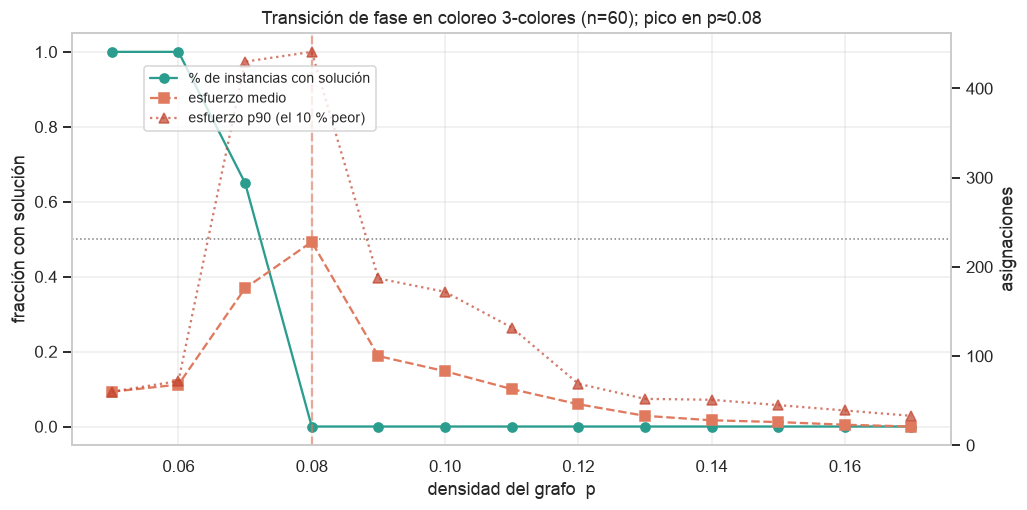


  Tres números que hay que leer juntos:
    · El 50 % de instancias con solución cae en p ≈ 0.07
    · El pico de esfuerzo medio cae en p ≈ 0.08
    · En el pico se gastan 228 asignaciones de media; en la zona
      sobre-restringida (p = 0.17), solo 21. Factor ×11.

  Los dos primeros caen en puntos contiguos de la grilla (el barrido avanza de
  0.01 en 0.01), o sea coinciden dentro de la resolución del experimento. ESO
  es la transición de fase: el problema más caro no es el más restringido, es
  el que está JUSTO EN EL LÍMITE, donde el algoritmo tiene que explorar
  muchísimo para decidir de qué lado cae. Si quieres afinar dónde está el punto
  crítico exacto, hay que reducir el paso de la grilla y subir INSTANCIAS.

  Fíjate también en la curva p90: el 10 % peor de las instancias cuesta mucho
  más que la media cerca del pico, y casi lo mismo lejos de él. Cerca del punto
  crítico la VARIANZA explota, no solo la media.

  Por qué importa fuera del examen:
  · Para COMPARAR algori

In [21]:
# Parámetros elegidos a propósito: con n pequeño y buenas heurísticas el pico se
# aplana y no se ve nada. Con n = 60 el fenómeno aparece con claridad.
N_NODOS, K, INSTANCIAS = 60, 3, 20
densidades = np.linspace(0.05, 0.17, 13)
filas = []
for p in densidades:
    resueltos, esfuerzos = 0, []
    for s in range(INSTANCIAS):
        csp = csp_coloreo_aleatorio(n=N_NODOS, p=float(p), k=K, semilla=1000 + s)
        sol = backtracking(csp, mrv, orden_natural, forward_checking,
                           limite_asignaciones=200_000)
        resueltos += sol not in (None, "LIMITE")
        esfuerzos.append(csp.m.asignaciones)
    filas.append({"densidad p": round(float(p), 3),
                  "aristas medias": round(p * N_NODOS * (N_NODOS - 1) / 2, 1),
                  "% con solución": resueltos / INSTANCIAS,
                  "asignaciones (media)": int(np.mean(esfuerzos)),
                  "asignaciones (p90)": int(np.percentile(esfuerzos, 90))})
tf = pd.DataFrame(filas)
display(tf)

fig, ax1 = plt.subplots(figsize=(9.5, 4.8))
ax1.plot(tf["densidad p"], tf["% con solución"], "o-", color="#2a9d8f",
         label="% de instancias con solución")
ax1.set(xlabel="densidad del grafo  p", ylabel="fracción con solución", ylim=(-.05, 1.05))
ax1.axhline(0.5, ls=":", c="gray", lw=1)
ax2 = ax1.twinx()
ax2.plot(tf["densidad p"], tf["asignaciones (media)"], "s--", color="#e07a5f",
         label="esfuerzo medio")
ax2.plot(tf["densidad p"], tf["asignaciones (p90)"], "^:", color="#c1452f",
         alpha=.7, label="esfuerzo p90 (el 10 % peor)")
ax2.set_ylabel("asignaciones"); ax2.grid(False)
pico = tf.loc[tf["asignaciones (media)"].idxmax(), "densidad p"]
ax1.axvline(pico, ls="--", c="#e07a5f", alpha=.6)
ax1.set_title(f"Transición de fase en coloreo 3-colores (n={N_NODOS}); pico en p≈{pico}")
fig.legend(loc="upper left", bbox_to_anchor=(0.14, 0.87), fontsize=9)
plt.tight_layout(); plt.show()

cruce = tf.iloc[(tf["% con solución"] - 0.5).abs().idxmin()]["densidad p"]
base = tf["asignaciones (media)"].iloc[-1]
print(f"""
  Tres números que hay que leer juntos:
    · El 50 % de instancias con solución cae en p ≈ {cruce}
    · El pico de esfuerzo medio cae en p ≈ {pico}
    · En el pico se gastan {tf['asignaciones (media)'].max():,} asignaciones de media; en la zona
      sobre-restringida (p = {tf['densidad p'].iloc[-1]}), solo {base:,}. Factor ×{tf['asignaciones (media)'].max()/max(base,1):.0f}.

  Los dos primeros caen en puntos contiguos de la grilla (el barrido avanza de
  0.01 en 0.01), o sea coinciden dentro de la resolución del experimento. ESO
  es la transición de fase: el problema más caro no es el más restringido, es
  el que está JUSTO EN EL LÍMITE, donde el algoritmo tiene que explorar
  muchísimo para decidir de qué lado cae. Si quieres afinar dónde está el punto
  crítico exacto, hay que reducir el paso de la grilla y subir INSTANCIAS.

  Fíjate también en la curva p90: el 10 % peor de las instancias cuesta mucho
  más que la media cerca del pico, y casi lo mismo lejos de él. Cerca del punto
  crítico la VARIANZA explota, no solo la media.

  Por qué importa fuera del examen:
  · Para COMPARAR algoritmos hay que hacerlo en la zona crítica. Medir fuera de
    ella hace que todo parezca igual de bueno — es el mismo error que vimos en
    §4 con Australia, que era demasiado fácil para distinguir nada.
  · Si tu problema real cae cerca del punto crítico, espera varianza enorme
    entre instancias parecidas. No es un bug de tu código.
  · Es el mismo fenómeno que en SAT (ratio cláusulas/variables ≈ 4.27 para
    3-SAT), y uno de los puentes entre la IA y la física estadística.""")

---

## 13. Resumen y siguiente paso

### Resumen en 6 líneas

1. Un CSP es búsqueda con **estados factorizados**: el algoritmo puede mirar dentro del
   estado, y de ahí sale toda la ganancia.
2. *Backtracking* es DFS con **una variable por nivel**; las heurísticas deciden cuánto
   cuesta.
3. **MRV + grado** eligen la variable (*fail first*); **LCV** elige el valor
   (*fail last*). Son opuestos a propósito.
4. **Forward checking** propaga una capa; **AC-3/MAC** propaga en **cascada** y detecta
   fallos que FC no ve, al precio de $O(cd^3)$.
5. **Min-conflicts** resuelve problemas con muchas soluciones a una velocidad
   ridícula, pero **no demuestra insatisfacibilidad**.
6. La **estructura** manda: componentes conexas gratis, árboles en $O(nd^2)$, *cutset*
   si casi es un árbol.

### Checklist antes de la Solemne

Marca solo lo que puedas hacer **sin mirar el notebook**:

- [ ] Formular un problema como $\langle X, D, C\rangle$ y dibujar su grafo.
- [ ] Ejecutar **AC-3 a mano** sobre un grafo pequeño, llevando la cola.
- [ ] Explicar el caso $NT$/$SA$ en que FC no ve el fallo y AC-3 sí.
- [ ] Justificar por qué MRV y LCV usan criterios opuestos.
- [ ] Enunciar el teorema del CSP en árbol y **por qué** no hace falta retroceder.
- [ ] Decir cuándo **no** usar min-conflicts.

### Siguiente paso

→ **Continúa en: NB-07/NB-08** — la lógica y la probabilidad. Una red bayesiana (NB-08)
usa **el mismo grafo** que viste aquí, con otra semántica: las aristas ya no son
restricciones duras sino dependencias probabilísticas, y la propagación de restricciones
se convierte en **propagación de creencias**. El parecido no es casual: ambos son
problemas de inferencia sobre grafos.

Y si estás con el proyecto de Big Data, §8.2 es el molde directo para programar
horarios con restricciones duras.

### Para profundizar

- *AIMA 4.ª ed.*, cap. 6 completo; en especial 6.2.5 (restricciones globales y la regla
  de conteo) y 6.5 (estructura del problema).
- Mackworth, A. (1977). *Consistency in networks of relations* — el paper de AC-3.
- Régin, J-C. (1994). *A filtering algorithm for constraints of difference* — el
  algoritmo de propagación de `Alldiff` con emparejamiento máximo.
- Cheeseman, Kanefsky & Taylor (1991). *Where the really hard problems are* — la
  transición de fase del Nivel 3.
- Google OR-Tools (CP-SAT): el solver que usarías en producción.